In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score, accuracy_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [2]:
data = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

!wget $data

--2026-10-12 11:38:09--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8001::154, 2606:50c0:8003::154, 2606:50c0:8000::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8001::154|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K   464KB/s    in 0.6s    

2026-10-12 11:38:11 (464 KB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



In [3]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 526.0 KB


In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [9]:
categorical = [c for c in df.columns if c != 'converted' and df[c].dtype == 'string']
numerical = [c for c in df.columns if c != 'converted' and c not in categorical]

In [10]:
print("\nCategorical:", categorical)
print("Numerical:  ", numerical)


Categorical: ['lead_source', 'industry', 'employment_status', 'location']
Numerical:   ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


In [14]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

print(df.isnull().sum())

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


# Q1

In [15]:
df['industry'].mode()[0]

'technology'

# Q2

In [16]:
corr = df[numerical].corr()
corr

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000


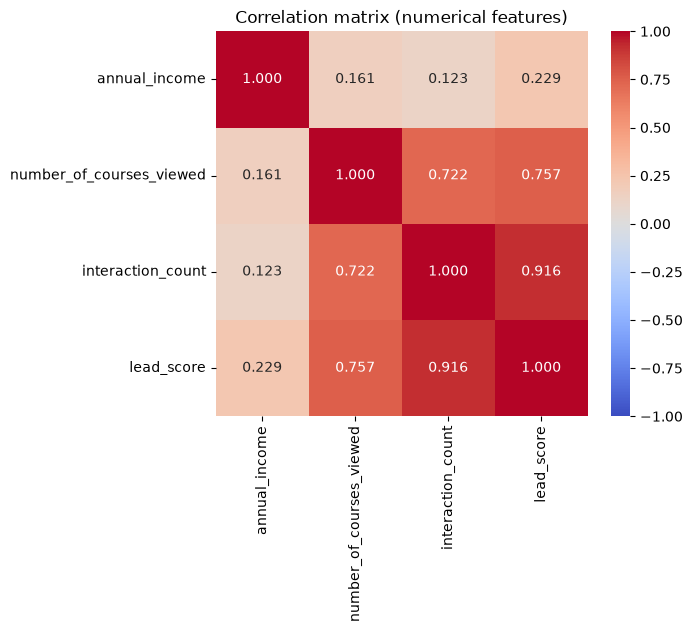

In [17]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix (numerical features)')
plt.show()

# Split

In [18]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

In [19]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [20]:
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

In [21]:
del df_train['converted']
del df_val['converted']
del df_test['converted']


In [22]:
len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## EDA

In [13]:
for c in categorical:
    print(c, df[c].nunique())
    print(df[c].value_counts())
    print()

lead_source 5
lead_source
organic_search    1251
paid_ads          1140
social_media      1055
referral           790
events             616
Name: count, dtype: int64

industry 6
industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
Name: count, dtype: int64

employment_status 4
employment_status
employed         2633
student           760
self_employed     715
unemployed        698
Name: count, dtype: int64

location 5
location
north_america    1371
europe           1149
asia             1052
south_america     749
africa            471
Name: count, dtype: int64



In [ ]:
print(df['converted'].value_counts())

converted
1    2883
0    2117
Name: count, dtype: int64

Global conversion rate: 0.5766


In [24]:
global_rate = df['converted'].mean()
print("Global conversion rate:", global_rate)

Global conversion rate: 0.5766


In [25]:
from IPython.display import display

for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).converted.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_rate
    df_group['risk'] = df_group['mean'] / global_rate
    display(df_group)
    print()
    print()

lead_source


,mean,count,diff,risk
lead_source,,,,
NA,0.610169,118,0.033569,1.058220
events,0.411290,496,-0.165310,0.713303
organic_search,0.677579,1008,0.100979,1.175129
paid_ads,0.427957,930,-0.148643,0.742208
referral,0.763844,614,0.187244,1.324738
social_media,0.547962,834,-0.028638,0.950332




industry


,mean,count,diff,risk
industry,,,,
NA,0.587629,194,0.011029,1.019127
education,0.500000,518,-0.076600,0.867152
finance,0.613402,582,0.036802,1.063826
healthcare,0.559398,665,-0.017202,0.970167
manufacturing,0.548969,388,-0.027631,0.952080
retail,0.553741,735,-0.022859,0.960356
technology,0.611111,918,0.034511,1.059853




employment_status


,mean,count,diff,risk
employment_status,,,,
NA,0.580247,162,0.003647,1.006325
employed,0.656459,2090,0.079859,1.138500
self_employed,0.548276,580,-0.028324,0.950877
student,0.419773,617,-0.156827,0.728014
unemployed,0.435572,551,-0.141028,0.755414




location


,mean,count,diff,risk
location,,,,
NA,0.603550,169,0.026950,1.046740
africa,0.546154,390,-0.030446,0.947197
asia,0.585308,844,0.008708,1.015102
europe,0.584821,896,0.008221,1.014258
north_america,0.576923,1092,0.000323,1.000560
south_america,0.525452,609,-0.051148,0.911293


## Q3. Mutual information

In [26]:
# apply to all categorical variables
def mutual_info_converted_score(series):
    return mutual_info_score(series, df_full_train.converted)

In [27]:
mi = df_full_train[categorical].apply(mutual_info_converted_score)
mi.sort_values(ascending=False)

lead_source          0.034761
employment_status    0.020313
industry             0.002898
location             0.001050
dtype: float64

## One-hot encoding

In [28]:
dv = DictVectorizer(sparse=False)

In [29]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')

In [30]:
X_train = dv.fit_transform(train_dicts)

In [31]:
val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

# Logistic Regression

In [35]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [36]:
y_pred = model.predict(X_val)
base_acc = accuracy_score(y_val, y_pred)

# Q4

In [38]:
round(base_acc, 2)

0.65

# Q5 Feature Elimination

In [41]:
features = categorical + numerical

rows = []

for f in features:
    # 1. Select all features except the current one
    subset = [c for c in features if c != f]
    
    # 2. Vectorize train and val using your existing DictVectorizer workflow
    dv = DictVectorizer(sparse=False)
    X_train_sub = dv.fit_transform(df_train[subset].to_dict(orient='records'))
    X_val_sub = dv.transform(df_val[subset].to_dict(orient='records'))
    
    # 3. Train model
    m = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    m.fit(X_train_sub, y_train)
    
    # 4. Score on validation and calculate difference from base_acc
    acc = accuracy_score(y_val, m.predict(X_val_sub))
    diff = base_acc - acc
    
    rows.append({'feature': f, 'accuracy_without': acc, 'difference': diff})

elim = pd.DataFrame(rows).sort_values('difference')
display(elim)

,feature,accuracy_without,difference
4,annual_income,0.724,-0.079
1,industry,0.645,0.000
3,location,0.645,0.000
2,employment_status,0.645,0.000
7,lead_score,0.644,0.001
5,number_of_courses_viewed,0.643,0.002
0,lead_source,0.642,0.003
6,interaction_count,0.601,0.044


In [ ]:
options = ['lead_source', 'number_of_courses_viewed', 'interaction_count']
feat = elim[elim['feature'].isin(options)].sort_values('difference')
display(feat)

,feature,accuracy_without,difference
5,number_of_courses_viewed,0.643,0.002
0,lead_source,0.642,0.003
6,interaction_count,0.601,0.044


In [45]:
C_values = [0.000001, 0.00001, 0.0001, 0.001]

scores = []

for C in C_values:
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_val)
    score = accuracy_score(y_val, y_pred)
    
    scores.append({
        'C': C,
        'accuracy': score,
        'accuracy_round_3': round(score, 3)
    })
    print(f"C={C} -> Accuracy: {score} (rounded: {round(score, 3)})")

df_scores = pd.DataFrame(scores)
display(df_scores)

C=1e-06 -> Accuracy: 0.598 (rounded: 0.598)
C=1e-05 -> Accuracy: 0.598 (rounded: 0.598)
C=0.0001 -> Accuracy: 0.613 (rounded: 0.613)
C=0.001 -> Accuracy: 0.645 (rounded: 0.645)


,C,accuracy,accuracy_round_3
0,0.000001,0.598,0.598
1,0.000010,0.598,0.598
2,0.000100,0.613,0.613
3,0.001000,0.645,0.645
